# 量子威胁评估 · Grover 放大与资源假设

QuantumBridge / 量子安全 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 未实现真实 RSA/AES 破解、Shor 大整数分解或容错资源评估。这个已知目标的 4 比特实验不能外推成真实密码被破解。

## 1. 原理与计算对象

在 16 个候选中标记已知字符串 1011，四个搜索比特加一个工作比特。相位预言机用 X、H、Toffoli 构造；工作位计算并反计算回 |0>，没有任意稠密酉黑箱。
Grover 迭代交替使用标记相位与关于均匀态的反射。单目标情况下 $\theta=\arcsin(1/\sqrt{16})$，r 次迭代成功率为 $\sin^2((2r+1)\theta)$。记录 0..5 次的原生概率并与公式核对，最后对 r=3 的电路采样。

预言机已经包含已知答案，是算法教学而非密码攻击。3 次预言机查询不等于 3 个基础门或 3 秒；真实密码的可逆预言机、纠错、连通性和门时长均不在这个查询模型里。

## 2. 实现步骤

1. 声明 4 比特搜索空间、已知标记态及工作位。
2. 构造基础门预言机和扩散步骤，核对工作位反计算。
3. 比较 0..5 次迭代的原生概率、解析公式与门数。
4. 对三次迭代电路采样，估计成功率与标准误。
5. 列出查询资源模型没有包含的硬件和密码代价。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import copy
import hashlib
import hmac
import json
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import ApplicationCase

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def four_bit_phase(circuit):
    circuit.ccx(0, 1, 4)
    circuit.h(3).ccx(2, 4, 3).h(3)
    circuit.ccx(0, 1, 4)


def grover_circuit(iterations, marked="1011"):
    if (
        type(iterations) is not int
        or not 0 <= iterations <= 8
        or len(marked) != 4
        or set(marked) - {"0", "1"}
    ):
        raise ValueError("Use a four-bit marked state and zero to eight iterations.")
    circuit = Circuit(5, name="four-bit-grover-one-work-wire")
    for q in range(4):
        circuit.h(q)
    for _ in range(iterations):
        for q, bit in enumerate(marked):
            if bit == "0":
                circuit.x(q)
        four_bit_phase(circuit)
        for q, bit in enumerate(marked):
            if bit == "0":
                circuit.x(q)
        for q in range(4):
            circuit.h(q).x(q)
        four_bit_phase(circuit)
        for q in range(4):
            circuit.x(q).h(q)
    return circuit


def threat_case():
    theta, marked = np.arcsin(1 / 4), "1011"
    device, rows = StatevectorDevice(), []
    for iterations in range(6):
        circuit = grover_circuit(iterations, marked)
        probability = device.probabilities(circuit).get(marked + "0", 0.0)
        rows.append(
            {
                "iterations": iterations,
                "oracle_queries": iterations,
                "primitive_gates": len(circuit.operations),
                "native_success_probability": probability,
                "analytic_success_probability": float(
                    np.sin((2 * iterations + 1) * theta) ** 2
                ),
            }
        )
    return ApplicationCase(
        "threat",
        "security",
        "Grover toy search and explicit logical-query assumptions",
        {
            "search_bits": 4,
            "candidates": 16,
            "marked": marked,
            "work_qubits": 1,
            "resource_model": "ideal oracle queries only; not seconds or physical qubits",
        },
        {
            "amplification_trace": rows,
            "chart_rows": [
                {
                    "label": str(row["iterations"]),
                    "value": row["native_success_probability"],
                }
                for row in rows
            ],
            "chart_units": "Success probability",
            "chart_title": "Grover iterations on a known toy oracle",
        },
        {
            "three_iteration_success": float(np.sin(7 * theta) ** 2),
            "classical_sequential_expected_queries": 8.5,
        },
        {"grover3": grover_circuit(3)},
        {
            "grover3": [
                float(bits[:4] == marked and bits[4] == "0") for bits in labels(5)
            ]
        },
        {
            "search_space": 16,
            "oracle_calls_per_run": 3,
            "rsa_or_aes_broken": False,
            "excluded_costs": [
                "real reversible cipher oracle",
                "fault tolerance",
                "routing",
                "physical error correction",
                "hardware runtime",
            ],
            "toy_oracle_contains_known_marked_value": True,
        },
    )


In [3]:
case = threat_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

iterations,oracle_queries,primitive_gates,native_success_probability,analytic_success_probability
0,0,4,0.0625,0.0625
1,1,32,0.47265625,0.47265625
2,2,60,0.90844727,0.90844727
3,3,88,0.96131897,0.96131897
4,4,116,0.58170414,0.58170414
5,5,144,0.12549168,0.12549168


label,value
0,0.0625
1,0.47265625
2,0.90844727
3,0.96131897
4,0.58170414
5,0.12549168


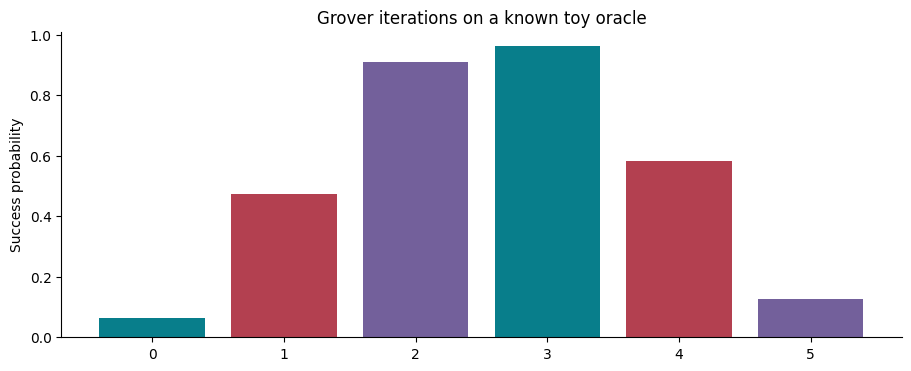

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
grover3,5,88,1024,20261023


observable,estimate,standard_error,ideal_reference
grover3,0.95800781,0.0062709156,0.96131897


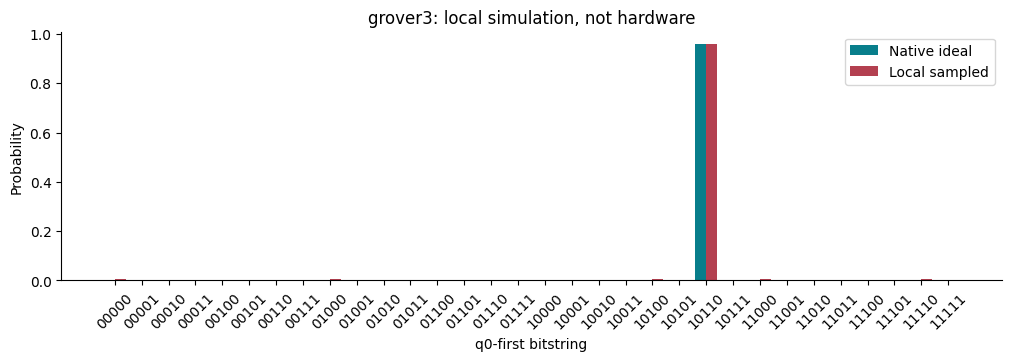

experiment,counts
grover3,"{""10110"": 981, ""10010"": 3, ""01000"": 5, ""11000"": 4, ""11110"": 6, ""00010"": 3, ""10000"": 3, ""00000"": 4, ""11100"": 3, ""10100"": 5, ""00110"": 1, ""11010"": 1, ""00100"": 1, ""01110"": 3, ""01100"": 1}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- grover3 ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[5];
creg c[5];
h q[0];
h q[1];
h q[2];
h q[3];
x q[1];
ccx q[0],q[1],q[4];
h q[3];
ccx q[2],q[4],q[3];
h q[3];
ccx q[0],q[1],q[4];
x q[1];
h q[0];
x q[0];
h q[1];
x q[1];
h q[2];
x q[2];
h q[3];
x q[3];
ccx q[0],q[1],q[4];
h q[3];
ccx q[2],q[4],q[3];
h q[3];
ccx q[0],q[1],q[4];
x q[0];
h q[0];
x q[1];
h q[1];
x q[2];
h q[2];
x q[3];
h q[3];
x q[1];
ccx q[0],q[1],q[4];
h q[3];
ccx q[2],q[4],q[3];
h q[3];
ccx q[0],q[1],q[4];
x q[1];
h q[0];
x q[0];
h q[1];
x q[1];
h q[2];
x q[2];
h q[3];
x q[3];
ccx q[0],q[1],q[4];
h q[3];
ccx q[2],q[4],q[3];
h q[3];
ccx q[0],q[1],q[4];
x q[0];
h q[0];
x q[1];
h q[1];
x q[2];
h q[2];
x q[3];
h q[3];
x q[1];
ccx q[0],q[1],q[4];
h q[3];
ccx q[2],q[4],q[3];
h q[3];
ccx q[0],q[1],q[4];
x q[1];
h q[0];
x q[0];
h q[1];
x q[1];
h q[2];
x q[2];
h q[3];
x q[3];
ccx q[0],q[1],q[4];
h q[3];
ccx q[2],q[4],q[3];
h q[3];
ccx q[0],q[1],q[4];
x q[0];
h q[0];
x q[1];
h q[1];
x q[2];
h q[2];
x q[3];
h q[3];
measu

## 8. 结果解释、复做与非目标

第三次迭代成功概率约 0.9613；继续迭代可能下降，图表会显示过旋转。比较查询次数必须同时说明单目标、均匀起态和理想预言机假设。

未实现真实 RSA/AES 破解、Shor 大整数分解或容错资源评估。这个已知目标的 4 比特实验不能外推成真实密码被破解。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/security/03_threat_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 03_threat_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [Grover 原始搜索算法论文](https://arxiv.org/abs/quant-ph/9605043)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。